In [2]:
import os
import pickle as pkl
import pandas as pd

from pydeseq2.dds import DeseqDataSet
from pydeseq2.default_inference import DefaultInference
from pydeseq2.ds import DeseqStats
from pydeseq2.utils import load_example_data

In [2]:
def check_id_duplicate(df, column_name):
    if df[column_name].duplicated().any():
        raise ValueError(f"dataframe: '{df}' , its' column: '{column_name}' has duplicate values")

In [4]:
base_path = "../../../../2nd_6samples_output"
# total_df_original = pd.read_csv(os.path.join(base_path, "total_meet_at_least_one_condition.csv"), sep=",")
total_df = pd.read_csv(os.path.join(base_path, "dataset2_DSS_then_control_mirna_count_gene_name.csv"), sep=",")
check_id_duplicate(total_df, "gene_name")
###new add start(add new filter step)2025.4.22
# columns_to_check = total_df_original.columns[1:]
# # print(columns_to_check)
# # print(total_df.head())
# print(total_df_original[total_df_original[columns_to_check].gt(0).sum(axis=1) >= 4])
# total_df = total_df_original[total_df_original[columns_to_check].gt(0).sum(axis=1) >= 4]
###new add end(add new filter step)

# first set the first column as index
total_df.set_index('gene_name', inplace=True)
# print(total_df.head())
###add normalization: each value in column/the sum of each column.
columns_normalize = total_df.columns
df_normalized_total = total_df.copy()
df_normalized_total[columns_normalize] = total_df[columns_normalize].div(total_df[columns_normalize].sum())
# print(df_normalized_total[columns_normalize].head())
df_normalized_total[columns_normalize] = df_normalized_total[columns_normalize].mul(10**6).astype(int)

total_df_transposed_normalized = df_normalized_total.T
# print(total_df_transposed_normalized.head())

# # print("unnormalized total_df:",total_df)
# total_df_transposed = total_df.T

meta_data = {'condition': ['D', 'D', 'D', 'C', 'C', 'C'], 'group': ['D', 'D', 'D', 'C', 'C', 'C']}
meta_data_total_df = pd.DataFrame(meta_data, index=["SRR18078869", "SRR18078868", "SRR18078867","SRR18078872", "SRR18078871", "SRR18078870"])
print(meta_data_total_df)

            condition group
SRR18078869         D     D
SRR18078868         D     D
SRR18078867         D     D
SRR18078872         C     C
SRR18078871         C     C
SRR18078870         C     C


In [5]:
inference = DefaultInference(n_cpus=1)

dds_total = DeseqDataSet(
    counts=total_df_transposed_normalized,
    metadata=meta_data_total_df,
    design_factors="condition",
    refit_cooks=True,
    inference=inference,
    # n_cpus=8, # n_cpus can be specified here or in the inference object
)
dds_total.deseq2()
stat_res_D_vs_C_total = DeseqStats(dds_total, contrast=["condition", "D", "C"], inference=inference)
stat_res_D_vs_C_total.summary()

Fitting size factors...
... done in 0.00 seconds.

Fitting dispersions...
... done in 9.97 seconds.

Fitting dispersion trend curve...
/home/yaolab/mzhou10/.conda/envs/pydeseq2/lib/python3.12/site-packages/pydeseq2/dds.py:715: UserWarning: The dispersion trend curve fitting did not converge. Switching to a mean-based dispersion trend.
  self._fit_parametric_dispersion_trend(vst)
... done in 0.23 seconds.

Fitting MAP dispersions...
... done in 11.49 seconds.

Fitting LFCs...
... done in 7.98 seconds.

Calculating cook's distance...
... done in 0.01 seconds.

Replacing 0 outlier genes.

Running Wald tests...


Log2 fold change & Wald test p-value: condition D vs C
               baseMean  log2FoldChange     lfcSE      stat    pvalue  \
gene_name                                                               
bantam      5488.223465        1.206379  1.122057  1.075149  0.282308   
bantam-a       0.000000             NaN       NaN       NaN       NaN   
bantam-b       0.806587        1.650072  1.946408  0.847752  0.396576   
bantam-c-1     1.406003       -0.865102  3.272999 -0.264315  0.791537   
bantam-c-2     1.406003       -0.865102  3.272999 -0.264315  0.791537   
...                 ...             ...       ...       ...       ...   
miR5560        0.000000             NaN       NaN       NaN       NaN   
miR6191        0.000000             NaN       NaN       NaN       NaN   
miR8032d       0.000000             NaN       NaN       NaN       NaN   
miR8048        0.000000             NaN       NaN       NaN       NaN   
miR8137        0.298251       -1.243065  4.429660 -0.280623  0.778999

... done in 1.48 seconds.



In [7]:

df_stat_res_D_vs_C_total = stat_res_D_vs_C_total.results_df 
# print(df_stat_res_E_vs_F_total.head())
# df_stat_res_E_vs_F_ecoli = stat_res_E_vs_F_ecoli.results_df 
df_stat_res_D_vs_C_total_sorted = df_stat_res_D_vs_C_total.sort_values(by='padj', ascending=True)
print(df_stat_res_D_vs_C_total_sorted.head())
# print(df_stat_res_E_vs_F_total_sorted.columns)
# check_id_duplicate(df_stat_res_E_vs_F_total_sorted, "sequence")
# df_stat_res_E_vs_F_ecoli_sorted = df_stat_res_E_vs_F_ecoli.sort_values(by='padj', ascending=True)
#print(df_stat_res_E_vs_F_total_sorted.head())
SAVE = True  # whether to save the outputs of this notebook
if SAVE:
    df_stat_res_D_vs_C_total_sorted.to_csv(os.path.join(base_path, "DESeq2_results_D_vs_C_mirna_count_normalize_input_any_gene_name.csv"), index=True)
    # df_stat_res_E_vs_F_total_sorted.to_csv(os.path.join(base_path, "DESeq2_results_E_vs_F_total_sequence_normalize_input_at_least_4_samples.csv"), index=True)
    

               baseMean  log2FoldChange     lfcSE       stat        pvalue  \
gene_name                                                                    
miR-LLT11b  2432.500620        5.264058  0.371173  14.182213  1.180634e-45   
miR-LLT11a  2432.500620        5.264058  0.371173  14.182213  1.180634e-45   
miR1098     4740.060707       -6.451973  0.552775 -11.671969  1.772722e-31   
miR5074     4944.124073        5.212473  0.452320  11.523859  1.000281e-30   
miR10210    1076.275761       -6.133174  0.672578  -9.118903  7.588840e-20   

                    padj  
gene_name                 
miR-LLT11b  3.782162e-42  
miR-LLT11a  3.782162e-42  
miR1098     3.785943e-28  
miR5074     1.602200e-27  
miR10210    9.724340e-17  


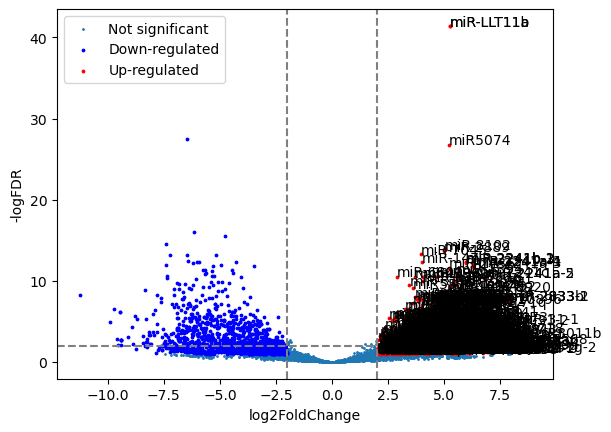

In [8]:
# import pandas as pd
# import matplotlib.pylab as plt
# # import seaborn as sns
# # from adjustText import adjust_text

# import numpy as np

# file_path = os.path.join(base_path, "DESeq2_results_D_vs_C_mirna_count_normalize_input_any_gene_name.csv")
# df = pd.read_csv(file_path, sep=",")
# df.set_index(df.columns[0], inplace=True)



# plt.scatter(x=df['log2FoldChange'],y=df['padj'].apply(lambda x:-np.log10(x)),s=1,label="Not significant")

# # highlight down- or up- regulated genes
# down = df[(df['log2FoldChange']<=-2)&(df['padj']<=0.1)]
# up = df[(df['log2FoldChange']>=2)&(df['padj']<=0.1)]

# plt.scatter(x=down['log2FoldChange'],y=down['padj'].apply(lambda x:-np.log10(x)),s=3,label="Down-regulated",color="blue")
# plt.scatter(x=up['log2FoldChange'],y=up['padj'].apply(lambda x:-np.log10(x)),s=3,label="Up-regulated",color="red")
# for i,r in up.iterrows():
#     plt.text(x=r['log2FoldChange'],y=-np.log10(r['padj']),s=i)

# plt.xlabel("log2FoldChange")
# plt.ylabel("-logFDR")
# plt.axvline(-2,color="grey",linestyle="--")
# plt.axvline(2,color="grey",linestyle="--")
# plt.axhline(2,color="grey",linestyle="--")
# plt.legend()


aaa


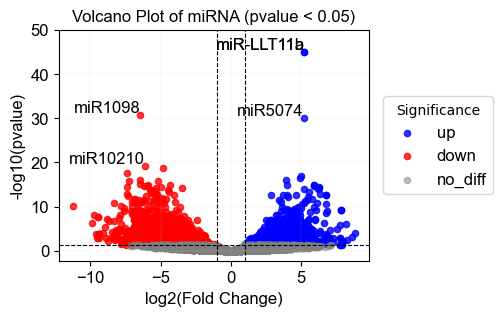

In [22]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt


import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.pyplot as plt
from matplotlib import font_manager as fm

fm.fontManager.addfont(str("arial.ttf"))

arial_font = fm.FontProperties(fname="arial.ttf", size=12)
print("aaa")

base_path = "../../../../2nd_6samples_output"
file_path = os.path.join(base_path, "DESeq2_results_D_vs_C_mirna_count_normalize_input_any_gene_name.csv")


data = pd.read_csv(file_path, sep=",", usecols=["gene_name", "log2FoldChange", "pvalue"])
#data = pd.read_csv(file_path, sep=",", usecols=["gene_name","log2FoldChange","padj"])
data = data.dropna(subset=["pvalue", "log2FoldChange"])  # Remove rows with missing values
data['pvalue'] = data['pvalue'].replace(0, 1e-300)          # Prevent -log10(0)
data['neg_log10_pvalue'] = -np.log10(data['pvalue'])

fc_thresh = 1
pvalue_thresh = 0.05

conditions = [
    (data['log2FoldChange'] > fc_thresh) & (data['pvalue'] < pvalue_thresh),
    (data['log2FoldChange'] < -fc_thresh) & (data['pvalue'] < pvalue_thresh),
]
choices = ['up', 'down']
data['significance'] = np.select(conditions, choices, default='no_diff')


plt.figure(figsize=(4, 3))
# colors = {'up': 'red', 'down': 'blue', 'no_diff': 'gray'}
colors = {'up': 'blue', 'down': 'red', 'no_diff': 'gray'}

for sig in colors:
    subset = data[data['significance'] == sig]
    plt.scatter(subset['log2FoldChange'], subset['neg_log10_pvalue'],
                color=colors[sig], label=sig, alpha=0.8 if sig != 'no_diff' else 0.5, s=20)

for _, row in data.nlargest(4, 'neg_log10_pvalue').iterrows():
    if row['significance'] == 'up':
        plt.text(row['log2FoldChange'], row['neg_log10_pvalue'], row['gene_name'],
                 fontproperties=arial_font, ha='right', va='bottom')
for _, row in data.nlargest(5, 'neg_log10_pvalue').iterrows():
    if row['significance'] == 'down':
        plt.text(row['log2FoldChange'], row['neg_log10_pvalue'], row['gene_name'],
                 fontproperties=arial_font, ha='right', va='bottom')

plt.axhline(-np.log10(pvalue_thresh), color='black', linestyle='--', linewidth=0.8)
plt.axvline(fc_thresh, color='black', linestyle='--', linewidth=0.8)
plt.axvline(-fc_thresh, color='black', linestyle='--', linewidth=0.8)

plt.xlabel('log2(Fold Change)',fontproperties=arial_font)
plt.ylabel('-log10(pvalue)',fontproperties=arial_font)
plt.ylim(top=50)
plt.title('Volcano Plot of miRNA (pvalue < 0.05)',fontproperties=arial_font)

plt.legend(title='Significance',prop=arial_font, loc='center left', bbox_to_anchor=(1.02, 0.5))

plt.xticks(fontproperties=arial_font)
plt.yticks(fontproperties=arial_font)

# plt.grid(True)
plt.grid(True, color="lightgray", linewidth=0.1)

# plt.show()
plt.savefig("supp_figureX_B.pdf", format="pdf", bbox_inches="tight")



aaa


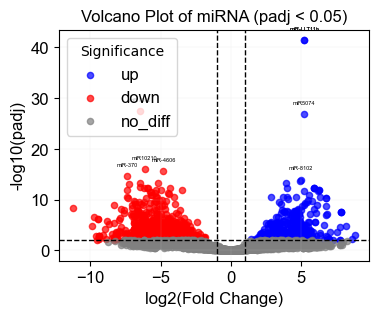

In [21]:
import pandas as pd
import numpy as np
import os
import matplotlib.pyplot as plt
import matplotlib.pyplot as plt
from matplotlib import font_manager as fm


fm.fontManager.addfont(str("arial.ttf"))

arial_font = fm.FontProperties(fname="arial.ttf", size=12)
arial_font_in = fm.FontProperties(fname="arial.ttf", size=4)
print("aaa")

base_path = "../../../../2nd_6samples_output"
file_path = os.path.join(base_path, "DESeq2_results_D_vs_C_mirna_count_normalize_input_any_gene_name.csv")
df = pd.read_csv(file_path, sep=",", usecols=["gene_name","log2FoldChange","padj"])

df = df.copy()
df = df[df['padj'].notnull()]  # Remove rows with NA padj
df['padj'] = df['padj'].replace(0, 1e-300)  # Avoid -log10(0) error

df['log10_padj'] = -np.log10(df['padj'])

fc_thresh = 1
pval_thresh = 0.01

conditions = [
    (df['log2FoldChange'] > fc_thresh) & (df['padj'] < pval_thresh),
    (df['log2FoldChange'] < -fc_thresh) & (df['padj'] < pval_thresh),
]
choices = ['up', 'down']
df['significance'] = np.select(conditions, choices, default='no_diff')

plt.figure(figsize=(4, 3))

colors = {'up': 'blue', 'down': 'red', 'no_diff': 'gray'}
# colors = {'up': '#A5CFEF', 'down': '#E7A6A6', 'no_diff': '#CFCFCF'}
for label, color in colors.items():
    subset = df[df['significance'] == label]
    plt.scatter(
        subset['log2FoldChange'],
        subset['log10_padj'],
        c=color, label=label, s=20, alpha=0.7
    )

plt.axhline(-np.log10(pval_thresh), color='black', linestyle='--', linewidth=1)
plt.axvline(fc_thresh, color='black', linestyle='--', linewidth=1)
plt.axvline(-fc_thresh, color='black', linestyle='--', linewidth=1)

top_labels = df[df['significance'] != 'no_diff']
top_labels = top_labels.sort_values('padj').head(8) # label top 10 by significance
top_labels_up = df[df['significance'] == 'up']
top_labels_up.to_excel("suppup.xlsx", index=False, header=True)
# print(top_labels_a.sort_values('padj'))
top_labels_down = df[df['significance'] == 'down']
top_labels_down.to_excel("suppdown.xlsx", index=False, header=True)

# print(top_labels)
# for row,gene_name in top_labels.iterrows():
#     print(gene_name)
#     plt.text(
#         row['log2FoldChange'],
#         row['log10_padj'] + 0.1,  # offset for clarity
#         gene_name,
#         fontsize=8,
#         ha='center'
#     )
for _, row in top_labels.iterrows():
    plt.text(
        row['log2FoldChange'],
        row['log10_padj']+2,
        row['gene_name'],   # assuming there's a 'gene_name' column
        ha='center',fontproperties=arial_font_in
    )

plt.xlabel('log2(Fold Change)',fontproperties=arial_font)
plt.ylabel('-log10(padj)',fontproperties=arial_font)
plt.title('Volcano Plot of miRNA (padj < 0.05)',fontproperties=arial_font)

plt.legend(title='Significance',prop=arial_font)

plt.xticks(fontproperties=arial_font)
plt.yticks(fontproperties=arial_font)

# plt.grid(True)
plt.grid(True, color="lightgray", linewidth=0.1)

# plt.show()
plt.savefig("figure2_D.pdf", format="pdf", bbox_inches="tight")

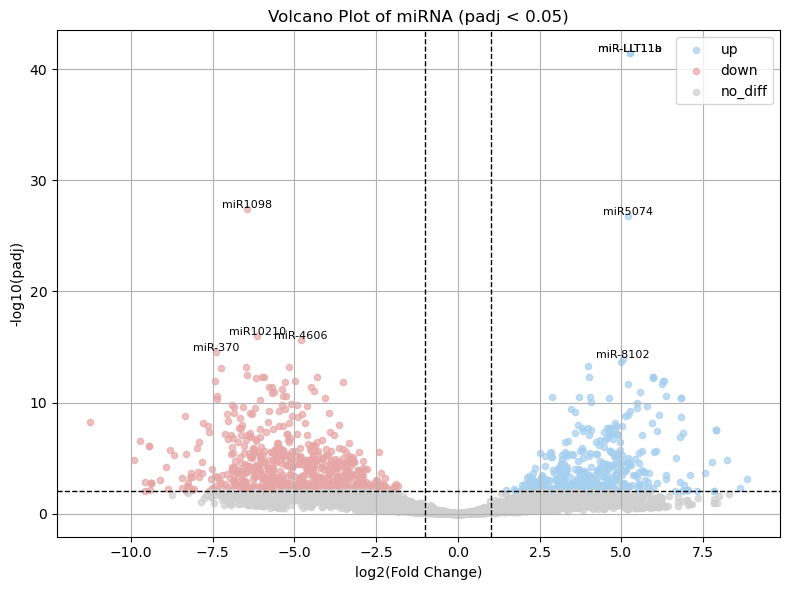

In [11]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt


base_path = "../../../../2nd_6samples_output"
file_path = os.path.join(base_path, "DESeq2_results_D_vs_C_mirna_count_normalize_input_any_gene_name.csv")
df = pd.read_csv(file_path, sep=",", usecols=["gene_name","log2FoldChange","padj"])


df = df.copy()
df = df[df['padj'].notnull()]  # Remove rows with NA padj
df['padj'] = df['padj'].replace(0, 1e-300)  # Avoid -log10(0) error


df['log10_padj'] = -np.log10(df['padj'])


fc_thresh = 1
pval_thresh = 0.05


conditions = [
    (df['log2FoldChange'] > fc_thresh) & (df['padj'] < pval_thresh),
    (df['log2FoldChange'] < -fc_thresh) & (df['padj'] < pval_thresh),
]
choices = ['up', 'down']
df['significance'] = np.select(conditions, choices, default='no_diff')


plt.figure(figsize=(8, 6))

# Color by significance
# colors = {'up': 'red', 'down': 'blue', 'no_diff': 'gray'}
colors = {'up': '#A5CFEF', 'down': '#E7A6A6', 'no_diff': '#CFCFCF'}
for label, color in colors.items():
    subset = df[df['significance'] == label]
    plt.scatter(
        subset['log2FoldChange'],
        subset['log10_padj'],
        c=color, label=label, s=20, alpha=0.7
    )


plt.axhline(-np.log10(pval_thresh), color='black', linestyle='--', linewidth=1)
plt.axvline(fc_thresh, color='black', linestyle='--', linewidth=1)
plt.axvline(-fc_thresh, color='black', linestyle='--', linewidth=1)

top_labels = df[df['significance'] != 'no_diff']
top_labels = top_labels.sort_values('padj').head(8) # label top 10 by significance
# print(top_labels)
# for row,gene_name in top_labels.iterrows():
#     print(gene_name)
#     plt.text(
#         row['log2FoldChange'],
#         row['log10_padj'] + 0.1,  # offset for clarity
#         gene_name,
#         fontsize=8,
#         ha='center'
#     )
for _, row in top_labels.iterrows():
    plt.text(
        row['log2FoldChange'],
        row['log10_padj'] + 0.1,
        row['gene_name'],   # assuming there's a 'gene_name' column
        fontsize=8,
        ha='center'
    )


plt.xlabel("log2(Fold Change)")
plt.ylabel("-log10(padj)")
plt.title("Volcano Plot of miRNA (padj < 0.05)")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()


aaa
      gene_name  log2FoldChange          padj
0    miR-LLT11b        5.264058  3.782162e-42
1    miR-LLT11a        5.264058  3.782162e-42
2       miR1098       -6.451973  3.785943e-28
3       miR5074        5.212473  1.602200e-27
4      miR10210       -6.133174  9.724340e-17
5      miR-4606       -4.791306  2.599896e-16
6       miR-370       -7.385285  2.860076e-15
7      miR-8102        5.038355  1.190645e-14
8      miR-2889        4.979169  2.216968e-14
9      miR-7045        3.964727  5.405397e-14
10     miR-3757       -5.151941  6.825523e-14
11     miR10188       -6.474765  6.825523e-14
12     miR-8301       -7.239682  7.260487e-14
13      miR-216       -6.436518  3.254552e-13
14      miR394b       -4.294742  4.544870e-13
15      miR-147        4.020396  4.793224e-13
16      miR1524       -5.923118  4.793224e-13
17  miR-2241b-1        5.976398  5.238963e-13
18  miR-2241b-2        5.976398  5.238963e-13
19   miR-10608b       -6.000075  5.489776e-13
20  miR-2241b-3        5.96312

/tmp/ipykernel_783616/3593280900.py:78: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  cbar.ax.set_yticklabels(cbar.ax.get_yticklabels(), fontproperties=arial_font)


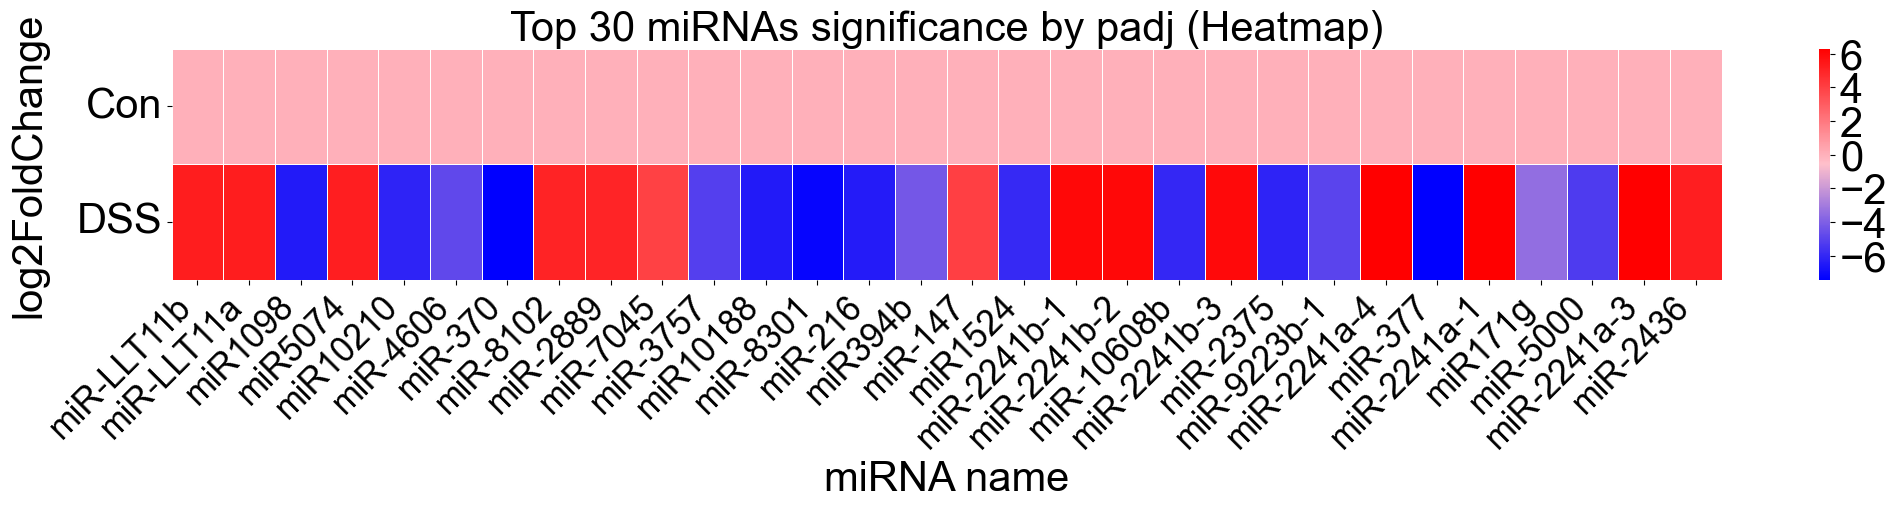

In [10]:
import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from matplotlib.colors import LinearSegmentedColormap
import matplotlib.pyplot as plt
from matplotlib import font_manager as fm

base_path = "../../../../2nd_6samples_output"
file_path = os.path.join(base_path, "DESeq2_results_D_vs_C_mirna_count_normalize_input_any_gene_name.csv")
df = pd.read_csv(file_path, sep=",", usecols=["gene_name","log2FoldChange","padj"])


df = df.copy()
df = df[df['padj'].notnull()]  # Remove rows with NA padj

fm.fontManager.addfont(str("arial.ttf"))


arial_font = fm.FontProperties(fname="arial.ttf", size=30)
print("aaa")
# Assuming df is your original DESeq2 result DataFrame
# df = pd.read_csv(...)


df = df.dropna(subset=["padj", "log2FoldChange"])
df = df.replace({'padj': 0}, 1e-300)  # Avoid -log10(0)


top_df = df.nsmallest(30, 'padj')
print(top_df)


custom_cmap = LinearSegmentedColormap.from_list(
    "custom_diverging",
    ["blue", "pink", "red"]  # blue → gray → red
)
heatmap_data = pd.DataFrame({
    'Con': np.zeros(len(top_df)),
    'DSS': top_df['log2FoldChange'].values
}, index=top_df['gene_name']).T  # rows: conditions, cols: miRNAs


significant = top_df['padj'] < 0.05

plt.figure(figsize=(25, 3))
# ax = sns.heatmap(
#     heatmap_data,
#     cmap="RdBu_r",
#     vmin=-3, vmax=1,
#     cbar_kws={'label': ''},
#     linewidths=0.5,
#     linecolor='white'
# )
ax = sns.heatmap(
    heatmap_data,
    cmap=custom_cmap,
    # vmin=-3, vmax=1,
    cbar_kws={'label': ''},
    linewidths=0.5,
    linecolor='white'
)
# # Add black dots for significant miRNAs
# for col_idx, (gene, sig) in enumerate(zip(top_df['sequence'], significant)):
#     if sig:
#         ax.add_patch(plt.Circle((col_idx + 0.5, 0.5), 0.08, color='black', zorder=10))


ax.set_xlabel("miRNA name", fontproperties=arial_font)
ax.set_xticklabels(top_df['gene_name'], rotation=45, ha='right',fontproperties=arial_font,size=25)
ax.set_yticklabels(['Con', 'DSS'], rotation=0,fontproperties=arial_font)
ax.set_ylabel("log2FoldChange", fontproperties=arial_font, labelpad=20)
plt.title('Top 30 miRNAs significance by padj (Heatmap)',fontproperties=arial_font)
cbar = ax.collections[0].colorbar
# cbar.set_label("Expression", fontproperties=arial_font, size=12)
cbar.ax.set_yticklabels(cbar.ax.get_yticklabels(), fontproperties=arial_font)
# Legend with Arial size 12
# plt.legend()
# plt.grid(True)
# plt.show()
plt.savefig("sipp_figureX_C.pdf", format="pdf", bbox_inches="tight")

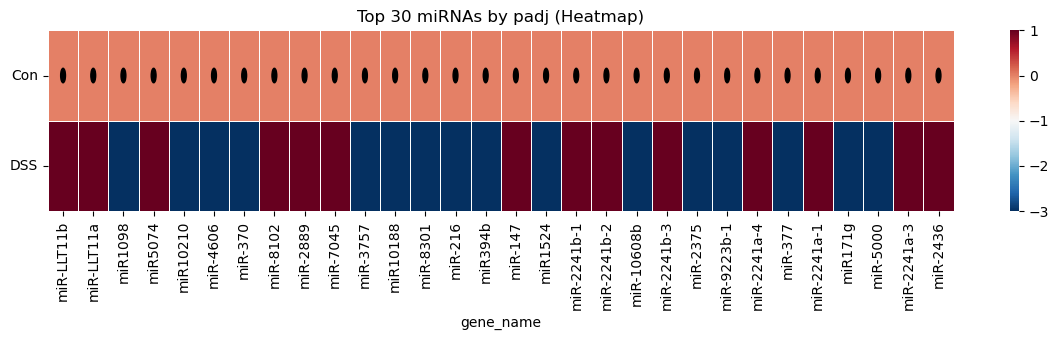

In [22]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns




df = df.dropna(subset=["padj", "log2FoldChange"])
df = df.replace({'padj': 0}, 1e-300)  # Avoid -log10(0)


top_df = df.nsmallest(30, 'padj')


heatmap_data = pd.DataFrame({
    'Con': np.zeros(len(top_df)),
    'DSS': top_df['log2FoldChange'].values
}, index=top_df['gene_name']).T  


significant = top_df['padj'] < 0.05


plt.figure(figsize=(12, 3.5))
ax = sns.heatmap(
    heatmap_data,
    cmap="RdBu_r",
    vmin=-3, vmax=1,
    cbar_kws={'label': ''},
    linewidths=0.5,
    linecolor='white'
)

for col_idx, (gene, sig) in enumerate(zip(top_df['gene_name'], significant)):
    if sig:
        ax.add_patch(plt.Circle((col_idx + 0.5, 0.5), 0.08, color='black', zorder=10))

ax.set_xticklabels(top_df['gene_name'], rotation=90)
ax.set_yticklabels(['Con', 'DSS'], rotation=0)
plt.title('Top 30 miRNAs by padj (Heatmap)')
plt.tight_layout()
plt.show()
